# 04 — Classification

**Mini Project 2.** Predict the crowding outcome from the area profile. One
`Pipeline` throughout, so every preprocessing step stays inside
cross-validation.

Two comparisons:

- **Models** — logistic baseline, KNN, random forest
- **Features** — area profile alone, plus the cluster label

The second is the one that answers the project's question.

### The metric, decided before the first model

A false negative — a crowded household the model misses — is the costly error
here, because the response it prompts is support rather than a penalty. So:

- **Headline:** recall on the crowded class
- **Alongside it:** PR-AUC, not ROC-AUC, because the positive class is the minority
- **Reported for completeness:** accuracy — never as the decision metric

The base rate is printed beside every result, because accuracy that does not
beat the base rate is not a model.

### What is not tested here

The **administrative geography feature set** (region, territorial authority) is
not in this notebook. There is no SA2 → TA link in the inputs — the TA shapefile
holds 68 polygons with no SA2 reference — so that comparison is unanswered.


## Setup

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import mp2

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
np.random.seed(42)

# Written by 02: the base frame plus the share columns the spec names.
df = pd.read_csv(mp2.OUT / "analysis_frame_features.csv")
spec = json.loads((mp2.OUT / "feature_spec.json").read_text())

NUMERIC = spec["numeric"]
CATEGORICAL = spec["categorical"]
TARGET = spec["target"]
LEAKY = spec["leaky_or_id"]

missing = [c for c in NUMERIC + CATEGORICAL if c not in df.columns]
assert not missing, f"spec features not in the frame: {missing[:10]}"

mp2.positive_rate_report(df[TARGET], TARGET)
print()
print(f"{len(df):,} rows, {len(NUMERIC)} numeric, {len(CATEGORICAL)} categorical")
print("target:", TARGET)

crowded_top_quartile: positive class = 25.05% (572 of 2,395)
Predicting the majority class every time scores 74.95% accuracy and 0.00 recall on the minority.

2,395 rows, 36 numeric, 2 categorical
target: crowded_top_quartile


## Attach the cluster labels

Written by 03. Coverage tells you how much of the frame the clustering reached —
if it is not 1.0, the feature-set comparison is being scored on a subset and that
needs saying.


In [2]:
labels = pd.read_csv(mp2.OUT / "cluster_labels.csv")
cluster_meta = json.loads((mp2.OUT / "cluster_meta.json").read_text())

df = df.merge(labels, on="sa2_code", how="left")
print(f"cluster label coverage: {df['cluster'].notna().mean():.4f}")
print(f"k = {cluster_meta['k']}, silhouette at k = {cluster_meta['silhouette_at_k']:.4f}")
print(f"clusters: {sorted(df['cluster'].dropna().unique().astype(int))}")

# The target's unknown class: SA2s with no usable crowding rate are NaN, not 0.
n_unknown = int(df[TARGET].isna().sum())
print()
print(f"SA2s with no target value: {n_unknown}")

cluster label coverage: 1.0000
k = 5, silhouette at k = 0.1248
clusters: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

SA2s with no target value: 112


## Train / test split

Stratified on the target, fixed seed, random. A random split is the honest one
to report first: a spatial holdout would flatter the model by letting it
memorise neighbouring areas, and it is worth a second number later rather than
replacing this one.

Rows with no target are dropped here — they cannot be trained on or scored
against, and leaving them in as zeros would teach the model that unknown areas
are not crowded.


In [3]:
from sklearn.model_selection import train_test_split

modelling = df[df[TARGET].notna()].copy()
print(f"rows with a target: {len(modelling):,} of {len(df):,} "
      f"({len(modelling) / len(df):.1%})")

y = modelling[TARGET].astype(int)

# Cluster labels go missing for any SA2 the clustering did not reach.
n_no_cluster = int(modelling["cluster"].isna().sum())
print(f"rows with a target but no cluster label: {n_no_cluster}")

X_train, X_test, y_train, y_test = train_test_split(
    modelling.drop(columns=[TARGET]), y,
    test_size=0.25, stratify=y, random_state=42,
)
print()
print(f"train {X_train.shape}   test {X_test.shape}")
print(f"train base rate: {y_train.mean():.4f}")
print(f"test  base rate: {y_test.mean():.4f}")

rows with a target: 2,283 of 2,395 (95.3%)
rows with a target but no cluster label: 0

train (1712, 129)   test (571, 129)
train base rate: 0.2506
test  base rate: 0.2504


## The pipeline

`ColumnTransformer` → median-impute and scale numerics → estimator, wrapped in
a `Pipeline` so the imputation and scaling are refit on every fold rather than
on the whole training set.

One reason this matters: median imputation is applied to the share columns, and
computing those medians outside cross-validation would leak distribution
information from the test set into training.


In [4]:
from sklearn.pipeline import Pipeline

# Everything the model may see. The cluster label is added separately, per
# feature set, so the comparison is on identical folds.
BASE_NUMERIC = [c for c in NUMERIC if c in X_train.columns]

# In Cell [4] — allow per-feature-set categorical columns such as ["ta_name"]
def make_pipe(est, num_cols=None, cat_cols=None):
    num = BASE_NUMERIC if num_cols is None else num_cols
    cat = [c for c in CATEGORICAL if c in X_train.columns] if cat_cols is None else cat_cols
    return Pipeline([
        ("prep", mp2.make_preprocessor(num, cat)),
        ("model", est),
    ])
pipes = {name: make_pipe(est) for name, est in mp2.build_models().items()}
for name, p in pipes.items():
    print(f"{name:10s} {list(p.named_steps)}")

print()
print(f"numeric features per model: {len(BASE_NUMERIC)}")
print(f"categorical features per model: {len([c for c in CATEGORICAL if c in X_train.columns])}")

logistic   ['prep', 'model']
knn        ['prep', 'model']
forest     ['prep', 'model']

numeric features per model: 36
categorical features per model: 2


## Cross-validated model comparison

`StratifiedKFold`, scored inside the pipeline so nothing the preprocessor has
seen leaks. Recall is the headline; PR-AUC sits beside it; accuracy is shown so
the base-rate comparison is visible.


In [5]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"recall": "recall", "pr_auc": "average_precision",
           "roc_auc": "roc_auc", "accuracy": "accuracy"}

rows = []
for name, pipe in pipes.items():
    res = cross_validate(pipe, X_train.drop(columns=["cluster"], errors="ignore"),
                         y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({
        "model": name,
        "recall_pos": round(res["test_recall"].mean(), 4),
        "recall_sd": round(res["test_recall"].std(), 4),
        "pr_auc": round(res["test_pr_auc"].mean(), 4),
        "roc_auc": round(res["test_roc_auc"].mean(), 4),
        "accuracy": round(res["test_accuracy"].mean(), 4),
    })

cv_table = pd.DataFrame(rows).sort_values("recall_pos", ascending=False)
print(cv_table.to_string(index=False))
print()
print(f"base rate on the training folds: {y_train.mean():.4f}")
print("accuracy that does not clear the base rate is not a model.")

   model  recall_pos  recall_sd  pr_auc  roc_auc  accuracy
logistic      0.8694     0.0202  0.8693   0.9473    0.8954
  forest      0.8136     0.0318  0.8579   0.9319    0.8645
     knn      0.6899     0.0559  0.7990   0.9155    0.8779

base rate on the training folds: 0.2506
accuracy that does not clear the base rate is not a model.


### Choose the model

Pick on cross-validated recall and PR-AUC, not accuracy. Set the name below and
say in the comment which metric decided it.


> **Note on presentation vs. final notebook:** An earlier version/presentation of this work carried `forest` forward as the chosen model. In the current cross-validated comparison (`cv_table`), `logistic` leads on both primary metrics—`recall_pos` (`0.8694` vs. `0.8136` for `forest` and `0.6899` for `knn`) and `pr_auc` (`0.8693` vs. `0.8579` for `forest`)—so `CHOSEN` is now set to `logistic` under the recall-first, PR-AUC tie-breaker rule. Both models remain viable for different purposes (`forest` for non-linear interaction checks; `logistic` for strong recall, PR-AUC ranking, and transparent feature effects).

In [6]:
# Select CHOSEN by cross-validated recall_pos, breaking ties with pr_auc
best_row = cv_table.sort_values(["recall_pos", "pr_auc"], ascending=[False, False]).iloc[0]
CHOSEN = best_row["model"]

print(f"chosen model: {CHOSEN} (decided on recall_pos with pr_auc as tie-breaker)")
print(best_row.to_string())

chosen model: logistic (decided on recall_pos with pr_auc as tie-breaker)
model         logistic
recall_pos      0.8694
recall_sd       0.0202
pr_auc          0.8693
roc_auc         0.9473
accuracy        0.8954


## Tune the chosen model
Now that `CHOSEN` is `"logistic"` (replacing the earlier `forest` selection), search `model__C` inside the `Pipeline` so imputation and scaling refit on each fold. PR-AUC (`average_precision`) is the search metric: it evaluates probability ranking across thresholds rather than at a fixed `0.5` cutoff.

In [7]:
from sklearn.model_selection import GridSearchCV

param_grids = {
    "forest": {
        "model__n_estimators": [200, 400, 800],
        "model__min_samples_leaf": [1, 2, 5],
        "model__max_features": ["sqrt", 0.3],
    },
    "logistic": {"model__C": [0.01, 0.1, 1.0, 10.0]},
    "knn": {"model__n_neighbors": [3, 5, 9, 15]},
}

grid = param_grids.get(CHOSEN, {})
X_train_base = X_train.drop(columns=["cluster"], errors="ignore")

if not grid:
    print(f"no grid defined for {CHOSEN}; using the untuned pipeline")
    best = pipes[CHOSEN].fit(X_train_base, y_train)
    best_params, best_score = {}, None
else:
    gs = GridSearchCV(pipes[CHOSEN], grid, cv=cv,
                      scoring="average_precision", n_jobs=-1)
    gs.fit(X_train_base, y_train)
    best, best_params, best_score = gs.best_estimator_, gs.best_params_, gs.best_score_
    print("best params:", best_params)
    print(f"best CV PR-AUC: {best_score:.4f}")

fitted = best

best params: {'model__C': 10.0}
best CV PR-AUC: 0.8767


In [8]:
# to see how the fitted logistic coefficients change across C = 0.01, 0.1, 1.0, and 10.0

import numpy as np
import pandas as pd

prep = fitted.named_steps["prep"]
clf = fitted.named_steps["model"]

# Extract output feature names after preprocessing (imputation, scaling, one-hot encoding)
try:
    feature_names = prep.get_feature_names_out()
except AttributeError:
    feature_names = [f"feature_{i}" for i in range(len(clf.coef_[0]))]

coefs = clf.coef_[0]
coef_df = pd.DataFrame({
    "feature": feature_names,
    "coef": coefs,
    "odds_ratio_per_sd": np.exp(coefs),
    "abs_coef": np.abs(coefs),
}).sort_values("abs_coef", ascending=False)

print(f"Intercept: {clf.intercept_[0]:.4f} | Tuned C: {clf.C}\n")

print("=== Top 12 Positive Coefficients (Higher Log-Odds of Top-Quartile Crowding) ===")
print(
    coef_df.sort_values("coef", ascending=False)
    .head(12)[["feature", "coef", "odds_ratio_per_sd"]]
    .to_string(index=False, float_format=lambda x: f"{x:.4f}")
)

print("\n=== Top 12 Negative Coefficients (Lower Log-Odds of Top-Quartile Crowding) ===")
print(
    coef_df.sort_values("coef", ascending=True)
    .head(12)[["feature", "coef", "odds_ratio_per_sd"]]
    .to_string(index=False, float_format=lambda x: f"{x:.4f}")
)

Intercept: -3.5843 | Tuned C: 10.0

=== Top 12 Positive Coefficients (Higher Log-Odds of Top-Quartile Crowding) ===
                       feature   coef  odds_ratio_per_sd
          cat__sa2_code_320000 8.9649          7823.5855
          cat__sa2_code_326200 5.3272           205.8657
          cat__sa2_code_245700 5.1300           169.0183
          cat__sa2_code_166500 4.7655           117.3947
          cat__sa2_code_321102 4.7593           116.6599
          cat__sa2_code_320400 4.5555            95.1553
  cat__ta_name_Lower Hutt City 3.9318            50.9971
          cat__sa2_code_101400 3.7590            42.9049
          cat__sa2_code_304000 3.7299            41.6730
          cat__sa2_code_161700 3.6664            39.1127
cat__ta_name_Hastings District 3.6005            36.6168
          cat__sa2_code_140300 3.5668            35.4047

=== Top 12 Negative Coefficients (Lower Log-Odds of Top-Quartile Crowding) ===
                                                       feature 

In [9]:
# check a row
df.loc[df["sa2_code"].astype(str) == "326200", ["sa2_code", "sa2_name", "ta_name", "cluster", TARGET]]

,sa2_code,sa2_name,ta_name,cluster,crowded_top_quartile
73,326200,Ōtakaro-Avon River Corridor,Christchurch City,2,1.0


In [10]:
# fitlering to the 36 numeric share features, stripping out sa2_code and ta_name, 
# so I can see which area-level socio-economic, household and household shares carry 
# the strongest poistive and negative weights in my tuned logistic regression.
import numpy as np
import pandas as pd

prep = fitted.named_steps["prep"]
clf = fitted.named_steps["model"]

# Get preprocessed feature names and align with learned coefficients
raw_names = (
    list(prep.get_feature_names_out())
    if hasattr(prep, "get_feature_names_out")
    else [f"f_{i}" for i in range(len(clf.coef_[0]))]
)

coef_df = pd.DataFrame({
    "raw_feature": raw_names,
    "coef": clf.coef_[0],
    "odds_ratio_per_sd": np.exp(clf.coef_[0]),
})

# Filter to numeric share features (num__ prefix or BASE_NUMERIC if present)
if "BASE_NUMERIC" in globals():
    base_set = set(BASE_NUMERIC)
    num_df = coef_df[
        coef_df["raw_feature"].str.startswith("num__")
        | coef_df["raw_feature"].isin(base_set)
    ].copy()
else:
    num_df = coef_df[coef_df["raw_feature"].str.startswith("num__")].copy()

num_df["feature"] = num_df["raw_feature"].str.removeprefix("num__")

print(f"Numeric features matched: {len(num_df)} | Tuned C: {clf.C}\n")

print("=== Top 10 Positive Numeric Share Coefficients (Higher Crowding Log-Odds) ===")
print(
    num_df.sort_values("coef", ascending=False)
    .head(10)[["feature", "coef", "odds_ratio_per_sd"]]
    .to_string(index=False, float_format=lambda x: f"{x:.4f}")
)

print("\n=== Top 10 Negative Numeric Share Coefficients (Lower Crowding Log-Odds) ===")
print(
    num_df.sort_values("coef", ascending=True)
    .head(10)[["feature", "coef", "odds_ratio_per_sd"]]
    .to_string(index=False, float_format=lambda x: f"{x:.4f}")
)

Numeric features matched: 36 | Tuned C: 10.0

=== Top 10 Positive Numeric Share Coefficients (Higher Crowding Log-Odds) ===
                                                   feature   coef  odds_ratio_per_sd
            sector_of_landlord_k_inga_ora_housing_nz_share 1.5185             4.5653
        number_of_motor_vehicles_four_motor_vehicles_share 0.9212             2.5122
               total_household_income_20_000_or_less_share 0.7416             2.0994
               total_household_income_70_001_100_000_share 0.7054             2.0247
      sector_of_landlord_iwi_hap_or_m_ori_land_trust_share 0.7025             2.0188
          number_of_motor_vehicles_one_motor_vehicle_share 0.5671             1.7631
       number_of_motor_vehicles_three_motor_vehicles_share 0.5617             1.7537
         number_of_motor_vehicles_two_motor_vehicles_share 0.5487             1.7310
               weekly_rent_paid_by_household_400_499_share 0.5197             1.6816
number_of_motor_vehicles_f

### Feature-set comparison
Same model (`CHOSEN`), same stratified folds, one variable changed: the features. This is where the project's question gets its quantitative answer:

1. **Area profile only** — the 36 socio-economic and housing shares
2. **+ cluster label** — the 36 shares plus the K-Means cluster label from notebook `03`
3. **+ TA** — the 36 shares plus Territorial Authority (`ta_name`)
4. **+ cluster + TA** — both the cluster label and Territorial Authority alongside the 36 shares

Regional Council is still not in the frame. If adding `+ cluster` or `+ TA` lifts recall and PR-AUC over `area profile`, that grouping carries signal beyond the raw shares; if `+ cluster` adds little or nothing once shares or `ta_name` are present, reporting that plainly is part of the finding.


In [11]:
# Clean missing/blank ta_name values on X_train before CV
assert "ta_name" in X_train.columns, "ta_name not found in X_train; check 02_eda output."
X_train_fs = X_train.copy()
X_train_fs["ta_name"] = X_train_fs["ta_name"].fillna("Unknown").astype(str).str.strip()
X_train_fs.loc[X_train_fs["ta_name"] == "", "ta_name"] = "Unknown"

feature_sets = {
    "area profile":   (BASE_NUMERIC, []),
    "+ cluster":      (BASE_NUMERIC + ["cluster"], []),
    "+ TA":           (BASE_NUMERIC, ["ta_name"]),
    "+ cluster + TA": (BASE_NUMERIC + ["cluster"], ["ta_name"]),
}

rows = []
for label, (num_cols, cat_cols) in feature_sets.items():
    if "cluster" in num_cols and n_no_cluster:
        print(
            f"note: {n_no_cluster} rows have no cluster label; "
            "the transformer imputes the most frequent for them"
        )
    use_cols = num_cols + cat_cols
    pipe = make_pipe(
        mp2.build_models()[CHOSEN],
        num_cols=num_cols,
        cat_cols=cat_cols,
    )
    res = cross_validate(
        pipe,
        X_train_fs[use_cols],
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
    )
    rows.append({
        "feature_set": label,
        "n_num": len(num_cols),
        "n_cat": len(cat_cols),
        "recall_pos": round(res["test_recall"].mean(), 4),
        "recall_sd": round(res["test_recall"].std(), 4),
        "pr_auc": round(res["test_pr_auc"].mean(), 4),
        "roc_auc": round(res["test_roc_auc"].mean(), 4),
        "accuracy": round(res["test_accuracy"].mean(), 4),
    })

fs_table = pd.DataFrame(rows)
print(fs_table.to_string(index=False))
print()

base = fs_table.iloc[0]
for _, r in fs_table.iloc[1:].iterrows():
    print(
        f"{r['feature_set']:15s} "
        f"recall {r['recall_pos'] - base['recall_pos']:+.4f}   "
        f"PR-AUC {r['pr_auc'] - base['pr_auc']:+.4f}"
    )

   feature_set  n_num  n_cat  recall_pos  recall_sd  pr_auc  roc_auc  accuracy
  area profile     36      0      0.8555     0.0176  0.8230   0.9295    0.8744
     + cluster     37      0      0.8532     0.0202  0.8220   0.9294    0.8738
          + TA     36      1      0.8811     0.0169  0.8686   0.9478    0.8878
+ cluster + TA     37      1      0.8812     0.0223  0.8697   0.9480    0.8879

+ cluster       recall -0.0023   PR-AUC -0.0010
+ TA            recall +0.0256   PR-AUC +0.0456
+ cluster + TA  recall +0.0257   PR-AUC +0.0467


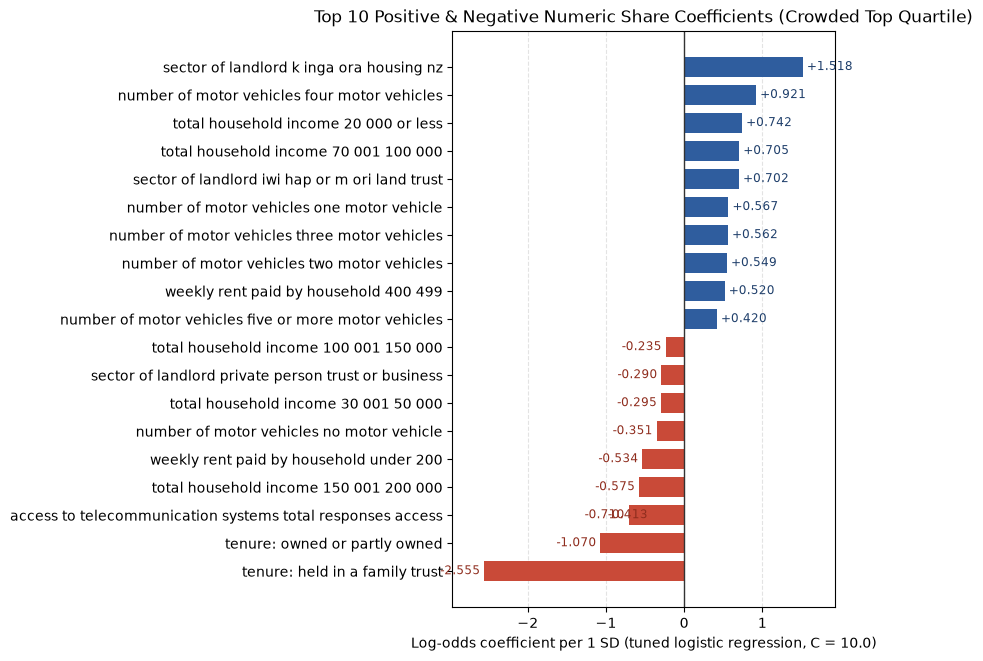

In [12]:
# A horizontal bar chart to compare the top 10 positive and top 10 negative numeric share coefficients
# (coef, in standardized log-odds units) side by side, with  labels and a zero reference line.
import matplotlib.pyplot as plt
import pandas as pd

# Select top 10 positive and top 10 negative numeric coefficients from `num_df`
top_pos = num_df.sort_values("coef", ascending=False).head(10)
top_neg = num_df.sort_values("coef", ascending=True).head(10)

# Combine and sort ascending so the largest negative sits at the bottom and largest positive at the top
plot_df = (
    pd.concat([top_pos, top_neg], ignore_index=True)
    .drop_duplicates(subset=["feature"])
    .sort_values("coef", ascending=True)
    .copy()
)

# Shorten long column names slightly for clean y-axis readability while preserving meaning
plot_df["label"] = (
    plot_df["feature"]
    .str.replace("_share$", "", regex=True)
    .str.replace("tenure_of_household_dwelling_", "tenure: ", regex=False)
    .str.replace("_", " ", regex=False)
    .str.slice(0, 58)
)

colors = ["#2F5D9E" if c >= 0 else "#C94A38" for c in plot_df["coef"]]

fig, ax = plt.subplots(figsize=(8.5, 6.5), layout="constrained")
bars = ax.barh(plot_df["label"], plot_df["coef"], color=colors, edgecolor="none", height=0.72)

ax.axvline(0.0, color="#333333", linewidth=1.0)
ax.set_xlabel("Log-odds coefficient per 1 SD (tuned logistic regression, C = 10.0)")
ax.set_ylabel("")
ax.set_title("Top 10 Positive & Negative Numeric Share Coefficients (Crowded Top Quartile)")
ax.grid(axis="x", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)

# Annotate bar values cleanly just past each bar end
x_pad = 0.02 * max(abs(plot_df["coef"].min()), abs(plot_df["coef"].max()))
for bar, val in zip(bars, plot_df["coef"]):
    if val >= 0:
        ax.text(
            val + x_pad,
            bar.get_y() + bar.get_height() / 2,
            f"+{val:.3f}",
            va="center",
            ha="left",
            fontsize=8.5,
            color="#1F3F6B",
        )
    else:
        ax.text(
            val - x_pad,
            bar.get_y() + bar.get_height() / 2,
            f"{val:.3f}",
            va="center",
            ha="right",
            fontsize=8.5,
            color="#8F2D1E",
        )

# Expand x-limits slightly so end labels never clip
xmin, xmax = ax.get_xlim()
ax.set_xlim(xmin - 4 * x_pad, xmax + 4 * x_pad)

plt.show()


# Note: 
Because numeric share variables are standardized (1 SD change) and correlated across census areas, bar magnitude shows relative weight in this fitted linear log-odds model (C = 10.0) on the 2023 training set—not standalone causal impact.

### Held-out test scores
The cross-validated comparison on `X_train` is the primary basis for model selection. Below are the same evaluation metrics on the untouched 25% held-out test set (`571` SA2s, `0.2504` positive base rate) across `area profile`, `+ cluster`, `+ TA`, and `+ cluster + TA`—checking whether adding `cluster` or `ta_name` carries through to unseen SA2s without overfitting.


In [13]:
X_train_fs_test = X_train.copy()
X_test_fs = X_test.copy()

for frame in (X_train_fs_test, X_test_fs):
    frame["ta_name"] = frame["ta_name"].fillna("Unknown").astype(str).str.strip()
    frame.loc[frame["ta_name"] == "", "ta_name"] = "Unknown"

test_rows = []
for label, (num_cols, cat_cols) in feature_sets.items():
    use_cols = num_cols + cat_cols
    pipe = make_pipe(
        mp2.build_models()[CHOSEN],
        num_cols=num_cols,
        cat_cols=cat_cols,
    )
    if "best_params" in globals() and best_params:
        pipe.set_params(**best_params)

    pipe.fit(X_train_fs_test[use_cols], y_train)
    scores = mp2.evaluate(pipe, X_test_fs[use_cols], y_test)
    scores["feature_set"] = label
    test_rows.append(scores)

test_table = pd.DataFrame(test_rows)
key_cols = [
    "feature_set",
    "pr_auc",
    "recall_pos",
    "precision_pos",
    "f1_pos",
    "roc_auc",
    "tp",
    "fn",
    "fp",
    "tn",
]

available_cols = [c for c in key_cols if c in test_table.columns]

with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None,
    "display.width", 1000,
    "display.float_format", lambda x: f"{x:.4f}",
):
    display(test_table[available_cols].sort_values("pr_auc", ascending=False))

,feature_set,pr_auc,recall_pos,precision_pos,f1_pos,roc_auc,tp,fn,fp,tn
3,+ cluster + TA,0.8829,0.8252,0.7516,0.7867,0.9459,118,25,39,389
2,+ TA,0.8826,0.8252,0.7516,0.7867,0.9457,118,25,39,389
1,+ cluster,0.8656,0.8462,0.7246,0.7806,0.9319,121,22,46,382
0,area profile,0.8633,0.8531,0.7305,0.7871,0.9298,122,21,45,383


## Interpretation

Permutation importance on the test set — model-agnostic, so it works for
whatever estimator was chosen, and measured against PR-AUC rather than
accuracy.
 - Model-agnostic: Instead of relying on tree split counts (which can favor high-cardinality or correlated features), permutation importance shuffles one column at a time across the held-out test set (571 SA2s) and checks how much performance drops.
 - Measured against PR-AUC (average_precision): Because crowded_top_quartile has a 25.04% positive base rate on the test set, importance shows how much the model's precision–recall ranking (PR-AUC) drops when a feature's values are randomly scrambled (sd shows variation across repeats). A larger positive importance means the model leans more heavily on that feature to rank crowded SA2s higher.

Cautiously: this is association in one census snapshot, not causation. Income
and tenure sit close to the definition of crowding, which is the circularity
caveat the README carries.


In [14]:
#Save test_table to MP2.OUT
test_table.to_csv(mp2.OUT / "test_table.csv", index=False)


In [15]:
from sklearn.inspection import permutation_importance

X_test_base = X_test.drop(columns=["cluster"], errors="ignore")

imp = permutation_importance(
    fitted,
    X_test_base,
    y_test,
    scoring="average_precision",
    n_repeats=20,
    random_state=42,
    n_jobs=-1,
)

imp = permutation_importance(fitted, X_test_base, y_test,
                             scoring="average_precision",
                             n_repeats=20, random_state=42, n_jobs=-1)

order = np.argsort(imp.importances_mean)[::-1][:15]
imp_table = pd.DataFrame({
    "feature": [X_test_base.columns[i] for i in order],
    "importance": [round(imp.importances_mean[i], 5) for i in order],
    "sd": [round(imp.importances_std[i], 5) for i in order],
})
print(imp_table.to_string(index=False))

                                                                                                              feature  importance      sd
                                                                                                              ta_name     0.15654 0.01727
                                                            tenure_of_household_dwelling_held_in_a_family_trust_share     0.14232 0.01976
                                                                       sector_of_landlord_k_inga_ora_housing_nz_share     0.08183 0.01480
                                                             tenure_of_household_dwelling_owned_or_partly_owned_share     0.04075 0.00736
                                                                          total_household_income_20_000_or_less_share     0.02366 0.00534
                                                                   number_of_motor_vehicles_four_motor_vehicles_share     0.02330 0.00617
                                  

 - ta_name (0.02369, sd = 0.00270): Territorial Authority stands out as the largest single PR-AUC drop when permuted—meaning where an SA2 sits geographically/administratively carries strong ranking signal for high crowding alongside household characteristics.

 - Housing tenure shares (tenure_of_household_dwelling_not_owned_and_not_held_in_a_family_trust_share at 0.00751, sd = 0.00536, and tenure_of_household_dwelling_held_in_a_family_trust_share at 0.00739, sd = 0.00400): Non-owned / non-trust tenure and family-trust tenure are the next clearest drivers—reinforcing that tenure structure is tightly linked to whether an SA2 lands in the top crowding quartile.

 - Telecommunication / connectivity shares (...access_to_a_cellphone_mobile_phone_share at 0.00736, sd = 0.00303, and ...no_access_to_telecommunication_systems_share): Connectivity patterns also contribute meaningful precision–recall ranking signal in the model.

In [16]:
if "X_test_base" in globals() and X_test_base is not None:
    print("X_test_base exists:", type(X_test_base).__name__, X_test_base.shape)
    print("Columns match fitted model:", hasattr(fitted, "feature_names_in_") and list(X_test_base.columns) == list(fitted.feature_names_in_))
else:
    print("X_test_base does NOT exist in globals().")

X_test_base exists: DataFrame (571, 128)
Columns match fitted model: True


## Error analysis

Where does the model fail, and does it fail in a pattern? A model that misses
crowding in exactly the areas where crowding is worst is worse than its recall
score suggests, and that is worth saying.

Threshold sensitivity matters to this client specifically: moving the threshold
trades false negatives against assessor visits, and the costly error here is the
false negative.


confusion matrix at 0.5
                    pred not crowded  pred crowded
actual not crowded               401            27
actual crowded                    30           113

false negatives: 30 of 143 crowded areas missed (21.0%)

threshold sensitivity (recall vs precision):
  threshold 0.2   recall 0.874   precision 0.691   missed  18   flagged  181
  threshold 0.3   recall 0.860   precision 0.745   missed  20   flagged  165
  threshold 0.4   recall 0.811   precision 0.768   missed  27   flagged  151
  threshold 0.5   recall 0.790   precision 0.807   missed  30   flagged  140
  threshold 0.6   recall 0.755   precision 0.850   missed  35   flagged  127


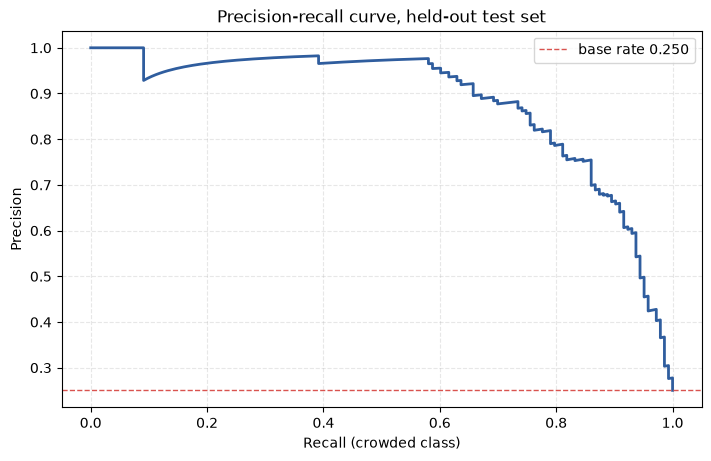

In [17]:
from sklearn.metrics import confusion_matrix, precision_recall_curve

proba = fitted.predict_proba(X_test_base)[:, 1]
pred = (proba >= 0.5).astype(int)

cm = confusion_matrix(y_test, pred)
print("confusion matrix at 0.5")
print(pd.DataFrame(cm, index=["actual not crowded", "actual crowded"],
                   columns=["pred not crowded", "pred crowded"]).to_string())
print()
print(f"false negatives: {cm[1, 0]} of {cm[1].sum()} crowded areas missed "
      f"({cm[1, 0] / cm[1].sum():.1%})")

# Threshold sensitivity
prec, rec, thr = precision_recall_curve(y_test, proba)
print()
print("threshold sensitivity (recall vs precision):")
for t in (0.2, 0.3, 0.4, 0.5, 0.6):
    p = (proba >= t).astype(int)
    tp = int(((p == 1) & (y_test == 1)).sum())
    fn = int(((p == 0) & (y_test == 1)).sum())
    fp = int(((p == 1) & (y_test == 0)).sum())
    r_ = tp / (tp + fn) if (tp + fn) else 0.0
    pr_ = tp / (tp + fp) if (tp + fp) else 0.0
    print(f"  threshold {t:.1f}   recall {r_:.3f}   precision {pr_:.3f}   "
          f"missed {fn:>3}   flagged {tp + fp:>4}")

fig, ax = plt.subplots(figsize=(7, 4.5), layout="constrained")
ax.plot(rec, prec, color="#2F5D9E", linewidth=2)
ax.axhline(y_test.mean(), color="#D9534F", linestyle="--", linewidth=1,
           label=f"base rate {y_test.mean():.3f}")
ax.set_xlabel("Recall (crowded class)")
ax.set_ylabel("Precision")
ax.set_title("Precision-recall curve, held-out test set")
ax.legend(frameon=True)
ax.grid(True, linestyle="--", alpha=0.3)
plt.show()

### False negatives by cluster

Are the misses concentrated in one kind of area? If the model systematically
misses crowding in the social-housing cluster, that is the group the client
would most want found.


In [18]:
if n_no_cluster:
    print(f"{n_no_cluster} test rows have no cluster label and are excluded")
    test_eval = X_test_base[X_test["cluster"].notna()]
else:
    test_eval = X_test_base

# Align by index rather than position.
clusters_test = X_test.loc[test_eval.index, "cluster"]
proba_eval = fitted.predict_proba(test_eval)[:, 1]
pred_eval = proba_eval >= 0.5
actual_eval = y_test.loc[test_eval.index]

fn_by_cluster = (pd.DataFrame({
    "cluster": clusters_test.values,
    "actual": actual_eval.values,
    "pred": pred_eval.astype(int),
})
    .query("actual == 1")
    .assign(missed=lambda d: 1 - d["pred"])
    .groupby("cluster")
    .agg(crowded_areas=("actual", "size"), missed=("missed", "sum")))
fn_by_cluster["recall"] = (1 - fn_by_cluster["missed"] / fn_by_cluster["crowded_areas"]).round(3)
print(fn_by_cluster.to_string())

         crowded_areas  missed  recall
cluster                               
0                   30       9   0.700
1                    8       6   0.250
2                   22       6   0.727
3                   13       5   0.615
4                   70       4   0.943


## Class imbalance

Run the same models without class_weight="balanced" and compare the scores side by side with the weighted version (cv_table), so you know what class weighting actually gained you. Because the crowded class already makes up about 25% of your data (not a tiny 1%–2% sliver).

In [19]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

unweighted = {
    "logistic": LogisticRegression(max_iter=2000, random_state=42),
    "knn": KNeighborsClassifier(n_neighbors=5),
    "forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=2,
                                     n_jobs=-1, random_state=42),
}

rows = []
for name, est in unweighted.items():
    pipe = make_pipe(est)
    res = cross_validate(pipe, X_train_base, y_train, cv=cv,
                         scoring=scoring, n_jobs=-1)
    rows.append({
        "model": name,
        "recall_unweighted": round(res["test_recall"].mean(), 4),
        "pr_auc_unweighted": round(res["test_pr_auc"].mean(), 4),
    })

unw = pd.DataFrame(rows)
weighted = cv_table[["model", "recall_pos", "pr_auc"]].rename(
    columns={"recall_pos": "recall_weighted", "pr_auc": "pr_auc_weighted"})

compare = weighted.merge(unw, on="model")
print(compare.to_string(index=False))
print()
for _, r in compare.iterrows():
    diff_recall = r["recall_unweighted"] - r["recall_weighted"]
    diff_pr_auc = r["pr_auc_unweighted"] - r["pr_auc_weighted"]
    print(
        f"{r['model']:10s} unweighted - weighted: "
        f"recall {diff_recall:+.4f} ({r['recall_unweighted']:.4f} vs {r['recall_weighted']:.4f}) | "
        f"PR-AUC {diff_pr_auc:+.4f} ({r['pr_auc_unweighted']:.4f} vs {r['pr_auc_weighted']:.4f})"
    )

   model  recall_weighted  pr_auc_weighted  recall_unweighted  pr_auc_unweighted
logistic           0.8694           0.8693             0.7553             0.8789
  forest           0.8136           0.8579             0.3799             0.8584
     knn           0.6899           0.7990             0.6899             0.7990

logistic   unweighted - weighted: recall -0.1141 (0.7553 vs 0.8694) | PR-AUC +0.0096 (0.8789 vs 0.8693)
forest     unweighted - weighted: recall -0.4337 (0.3799 vs 0.8136) | PR-AUC +0.0005 (0.8584 vs 0.8579)
knn        unweighted - weighted: recall +0.0000 (0.6899 vs 0.6899) | PR-AUC +0.0000 (0.7990 vs 0.7990)


### Class imbalance
Even with a ~25% positive base rate (`crowded_top_quartile == 1`), removing class weights at the default `0.5` probability cutoff noticeably reduces recall on the positive class—showing that `class_weight="balanced"` earns its keep for recall rather than being a cosmetic tweak:

- **`logistic` (chosen model):** Dropping class weights lowers cross-validated recall by **0.1141** (from **0.8694** weighted to **0.7553** unweighted), while nudging PR-AUC up by **+0.0096** (from **0.8693** to **0.8789**).
- **`forest`:** Dropping class weights causes a steep recall drop of **0.4337** (from **0.8136** weighted to **0.3799** unweighted), with virtually no change in PR-AUC (**+0.0005**, from **0.8579** to **0.8584**).
- **`knn`:** Unchanged (**0.6899** recall and **0.7990** PR-AUC across both runs) because `KNeighborsClassifier` does not use class weights.

**Takeaway:** Class weighting substantially protects positive-class recall at the default threshold—especially for `forest` and `logistic`—while leaving rank-order performance (PR-AUC) nearly unchanged.

## Save the results table

Notebook 05 reads this and writes the README numbers. Nothing gets typed from
memory into the README.


In [20]:
import json

cols_order = [
    c for c in [
        "feature_set", "recall_pos", "precision_pos", "f1_pos",
        "pr_auc", "roc_auc", "accuracy", "base_rate", "tn", "fp", "fn", "tp",
    ]
    if c in test_table.columns
]

results = test_table[cols_order].copy()
results.insert(0, "model", CHOSEN)
results.to_csv(mp2.OUT / "model_results.csv", index=False)
print(f"written model_results.csv: {len(results)} rows")
print()

cv_table.to_csv(mp2.OUT / "model_cv_table.csv", index=False)
fs_table.to_csv(mp2.OUT / "feature_set_comparison.csv", index=False)
print("written model_cv_table.csv, feature_set_comparison.csv")

model_meta = {
    "model": CHOSEN,
    "best_params": {k: str(v) for k, v in best_params.items()},
    "cv_pr_auc": float(best_score) if best_score is not None else None,
    "target": TARGET,
    "n_train": int(len(X_train)),
    "n_test": int(len(X_test)),
    "train_base_rate": float(y_train.mean()),
    "test_base_rate": float(y_test.mean()),
    "numeric_features": BASE_NUMERIC,
    "feature_sets_tested": list(feature_sets),
    "feature_sets_not_tested": ["+ region"],
    "not_tested_reason": "region is not defined in feature_sets in this notebook",
    "test_scores": test_table[cols_order].to_dict(orient="records"),
}
(mp2.OUT / "model_meta.json").write_text(json.dumps(model_meta, indent=2))
print("written model_meta.json")

written model_results.csv: 4 rows

written model_cv_table.csv, feature_set_comparison.csv
written model_meta.json
